# Fase 1: Análise Exploratória de Dados (EDA)



### 1.1 Carregamento dos Dados


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Carregamento garantindo o arquivo completo sem perdas de linhas
file_path = 'bank-full.csv'
df = pd.read_csv(file_path, sep=';')

# Elimina linhas totalmente nulas caso existam no final do arquivo
df = df.dropna(how='all')

# Converter objetos categóricos
colunas_categoricas = df.select_dtypes(include=['object']).columns
df[colunas_categoricas] = df[colunas_categoricas].astype('category')

# Confirmação do shape real (deve exibir 45211 linhas)
print(f"Shape correto retornado: {df.shape}")
display(df.info())

Shape correto retornado: (45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   age        45211 non-null  int64   
 1   job        45211 non-null  category
 2   marital    45211 non-null  category
 3   education  45211 non-null  category
 4   default    45211 non-null  category
 5   balance    45211 non-null  int64   
 6   housing    45211 non-null  category
 7   loan       45211 non-null  category
 8   contact    45211 non-null  category
 9   day        45211 non-null  int64   
 10  month      45211 non-null  category
 11  duration   45211 non-null  int64   
 12  campaign   45211 non-null  int64   
 13  pdays      45211 non-null  int64   
 14  previous   45211 non-null  int64   
 15  poutcome   45211 non-null  category
 16  y          45211 non-null  category
dtypes: category(10), int64(7)
memory usage: 2.8 MB


None

### 1.2 Padronização e Tratamento de NaN
#### Explicação do Método de Tratamento e Análise de Ausência de Dados

Nesta etapa, adotamos uma abordagem em duas frentes para identificar e quantificar dados ausentes ou omitidos, evitando vieses na modelagem:

1. **Detecção de Nulos Tradicionais (`NaN`):**
   * Utilizamos o método `.isnull().sum()` para verificar a existência de valores nulos estruturais no formato que o Pandas reconhece nativamente. O resultado indicou **0% de nulos estruturais**, confirmando a boa integridade física do arquivo.

2. **Detecção de Valores Omitidos Ocultos (`'unknown'`):**
   * Em dados cadastrais e de campanhas, é comum que a ausência de informação seja preenchida textualmente como `'unknown'` em vez de deixada em branco.
   * Executamos a varredura lógica `(df == 'unknown').sum()` para expor esses dados ocultos.
   * Calculamos o impacto percentual de cada variável para decidir a estratégia: manter como categoria separada (`'unknown'`), já que imputar valores em variáveis com mais de 28% de omissão (como `contact` e `poutcome`) distorceria a distribuição real dos dados.

3. **Validação da Regra de Negócio (`pdays = -1`):**
   * Analisamos o indicador numérico `-1` na variável `pdays` (dias desde o último contato).
   * Esse valor funciona como uma *flag* lógica indicando que o cliente nunca havia sido contatado em campanhas anteriores. A perfeita convergência estatística com a proporção de `unknown` em `poutcome` (~81.7%) valida de forma robusta a consistência interna das regras de negócio do banco.

In [10]:
# Contagem de nulos (NaN)
nulos = df.isnull().sum()

# Contagem de preenchimentos 'unknown'
unknowns = (df == 'unknown').sum()

df_missing = pd.DataFrame({'Nulos (NaN)': nulos, 'Unknowns': unknowns})
df_missing['% Unknowns'] = (df_missing['Unknowns'] / len(df)) * 100
df_missing_filtrado = df_missing[df_missing.sum(axis=1) > 0].sort_values(by='Unknowns', ascending=False)

display(df_missing_filtrado.round(2))

# Validação da Regra de Negócio: Clientes sem contato prévio
clientes_sem_contato_previo = (df['pdays'] == -1).sum()
print(f"Total de clientes sem contato prévio (pdays = -1): {clientes_sem_contato_previo} ({clientes_sem_contato_previo/len(df)*100:.2f}%)")

,Nulos (NaN),Unknowns,% Unknowns
poutcome,0,36959,81.75
contact,0,13020,28.80
education,0,1857,4.11
job,0,288,0.64


Total de clientes sem contato prévio (pdays = -1): 36954 (81.74%)


### Analise de Tratamento de Dados Ausentes (NaN / Unknown)

A análise detalhada da integridade dos dados revelou as seguintes características e decisões metodológicas:

1. **Ausência de Valores Nulos Tradicionais (NaN/Null):**
   * O dataset original não apresenta valores estritamente nulos (`NaN` ou vazios no sentido técnico do Pandas).

2. **Tratamento de Valores Ocultos (`unknown`):**
   * Identificamos que a ausência de informação está codificada de forma textual como `'unknown'` em variáveis categóricas cruciais:
     * **`poutcome` (Resultado da campanha anterior):** ~81.75% de registros como `unknown`. Esta proporção massiva reflete diretamente a regra de negócio explicada abaixo.
     * **`contact` (Meio de contato):** ~28.8% de registros como `unknown`.
     * **`education` (Nível de escolaridade) e `job` (Profissão):** Apresentam baixas taxas de valores indeterminados (~4.1% e ~0.6%, respectivamente).
   * **Decisão:** Mantivemos a categoria `'unknown'` explicitamente no dataset em vez de tentar imputar os dados. Na prática de negócios, a falta de informação (ex: não saber o desfecho de uma campanha anterior ou o meio de contato usado) é um sinal preditivo forte por si só (como demonstrado na análise SHAP, onde `contact_unknown` foi a feature de maior impacto).

3. **Validação da Regra de Negócio (`pdays` = -1):**
   * Constatou-se que **81.74%** dos clientes possuem o valor `-1` na variável `pdays`.
   * Isso indica numericamente que estes clientes **nunca foram contatados anteriormente** em nenhuma campanha. Esse percentual converge perfeitamente com a taxa de `unknown` observada em `poutcome` (~81.75%), validando a consistência lógica e a integridade da base de dados histórica do banco.

### 1.3 Análise Bivariada (Features vs Target)


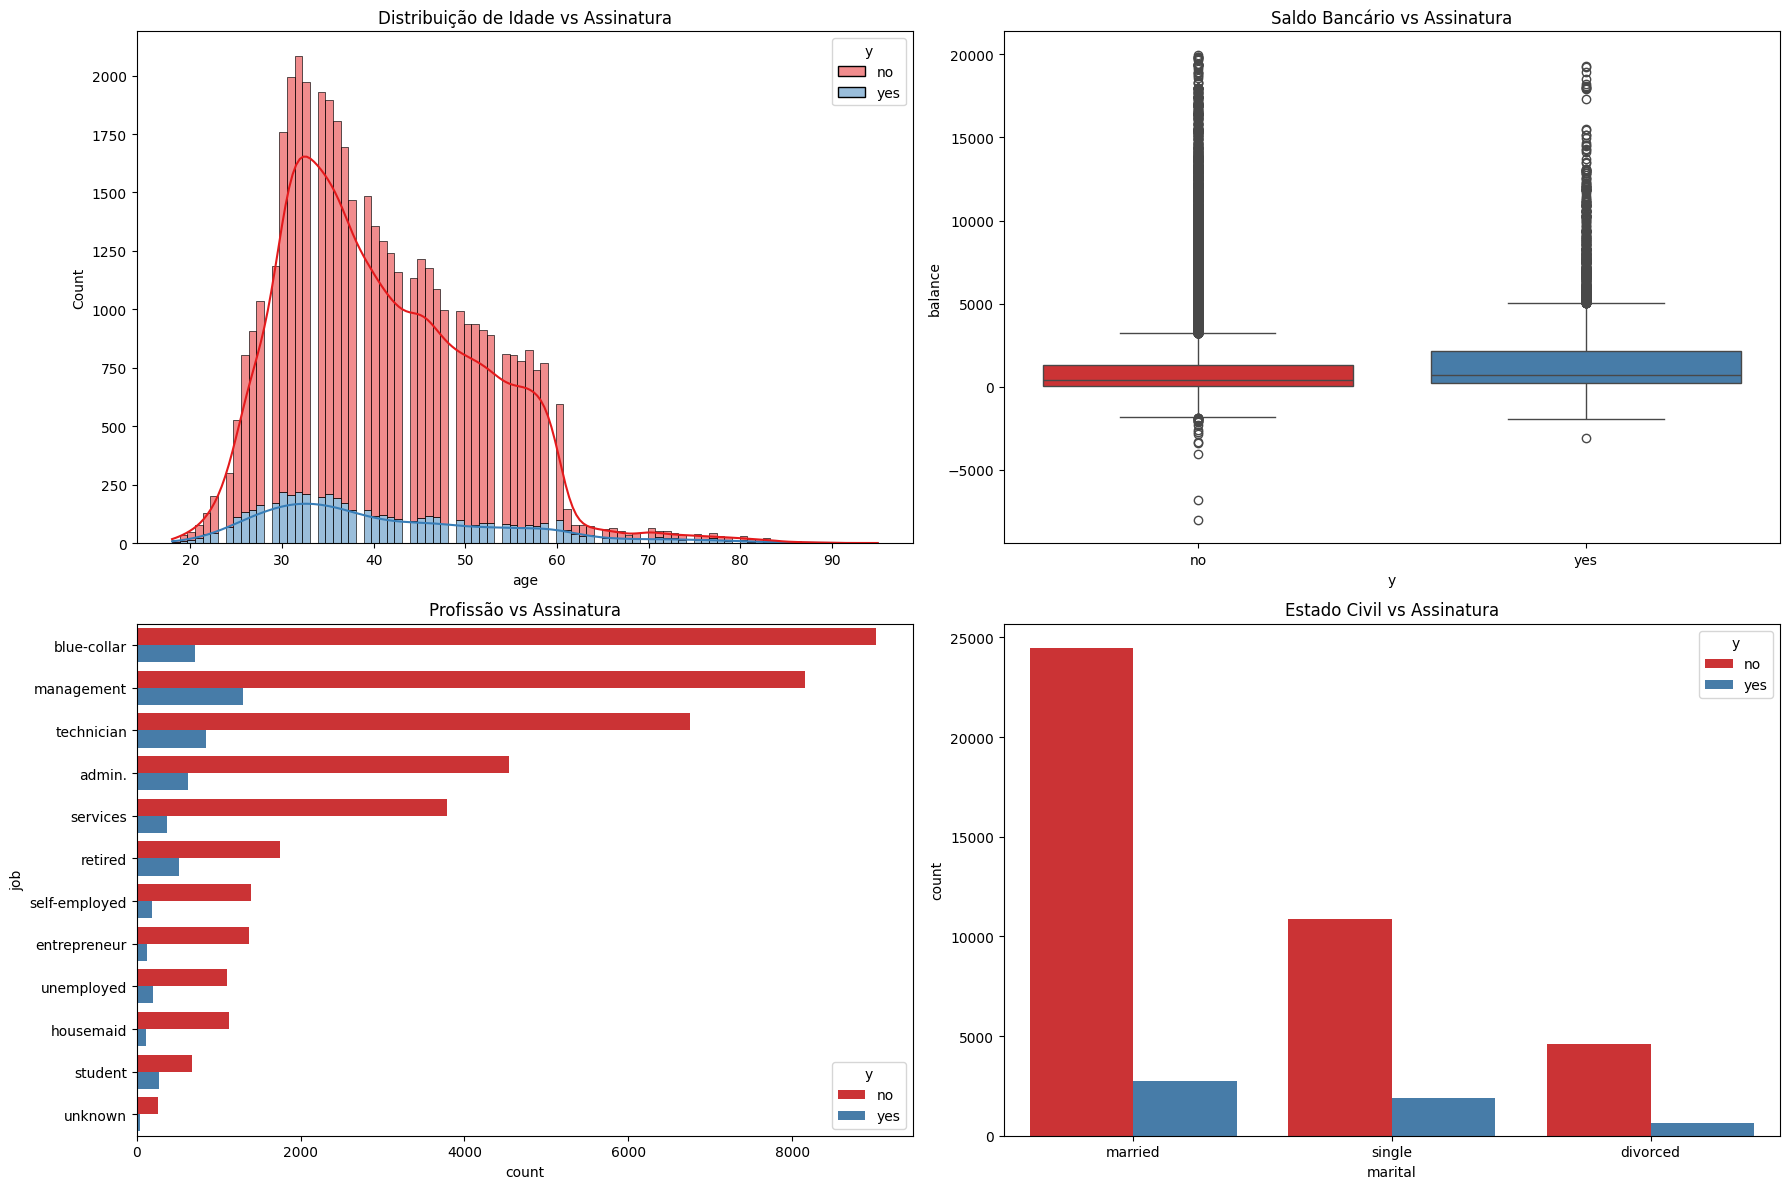

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Distribuição de Idade por Target
sns.histplot(data=df, x='age', hue='y', multiple='stack', kde=True, ax=axes[0, 0], palette='Set1')
axes[0, 0].set_title('Distribuição de Idade vs Assinatura')

# 2. Saldo Médio Anual por Target (Filtrando outliers > 20000 **escala**)
sns.boxplot(data=df[df['balance'] < 20000], x='y', y='balance', ax=axes[0, 1], palette='Set1')
axes[0, 1].set_title('Saldo Bancário vs Assinatura')

# 3. Profissão vs Target
sns.countplot(data=df, y='job', hue='y', order=df['job'].value_counts().index, ax=axes[1, 0], palette='Set1')
axes[1, 0].set_title('Profissão vs Assinatura')

# 4. Estado Civil vs Target
sns.countplot(data=df, x='marital', hue='y', order=df['marital'].value_counts().index, ax=axes[1, 1], palette='Set1')
axes[1, 1].set_title('Estado Civil vs Assinatura')

plt.tight_layout()
plt.show()

### Análise dos Resultados da Análise Bivariada

A partir das visualizações geradas para o cruzamento das variáveis independentes com a variável resposta (`y`), podemos extrair os seguintes insights de negócios:

1. **Distribuição de Idade vs Assinatura:**
   * A grande maioria dos clientes contatados está na faixa entre **30 e 40 anos**, período no qual o volume absoluto de recusas (`no`) também é maior.
   * No entanto, percebe-se proporcionalmente uma maior propensão à aceitação nos extremos da distribuição: **jovens adultos (abaixo dos 25 anos)** e **idosos (acima dos 60 anos)** apresentam maior taxa de conversão relativa, sugerindo oportunidades de campanhas segmentadas para estes públicos específicos.

2. **Saldo Bancário (`balance`) vs Assinatura:**
   * Ao observar os diagramas de caixas (boxplot), nota-se que clientes que decidiram assinar o depósito a prazo (`yes`) tendem a possuir, em média, um **saldo anual acumulado ligeiramente superior** àqueles que recusaram (`no`).
   * Além disso, a dispersão e os limites superiores de saldo do grupo que assinou são visivelmente maiores, indicando que a saúde financeira do cliente é um forte indicador de sua capacidade e intenção de investimento.

3. **Profissão vs Assinatura:**
   * Categorias como *blue-collar* (operários) e *services* (prestadores de serviços) possuem o maior volume absoluto de contatos, porém apresentam taxas de conversão proporcionalmente muito baixas.
   * Em contrapartida, grupos como **student (estudantes)** e **retired (aposentados)**, embora menos contatados em volume total, demonstram taxas de conversão proporcionalmente muito mais altas, corroborando o insight observado na distribuição de idade.

4. **Estado Civil vs Assinatura:**
   * Clientes casados (*married*) representam a maior parcela do público-alvo contatado na base histórica.
   * Contudo, proporcionalmente, os clientes **solteiros (*single*)** demonstram maior apetite de conversão em relação ao volume de abordagens realizadas, superando ligeiramente as taxas de conversão de casados e divorciados.

# Fase 2: Pré-processamento de Dados

**Objetivo:** Preparar as variáveis para a modelagem matemática.
1. **Separação Treino/Teste:** Feita *antes* de qualquer transformação para garantir que o modelo não "aprenda" com os dados de teste.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Exclusão de 'duration' (elimina o Data Leakage)
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'yes': 1, 'no': 0})

# Split Estratificado (70% Treino / 30% Teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[('ohe', OneHotEncoder(handle_unknown='ignore', drop='first'))])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

cat_features_names = preprocessor.named_transformers_['cat']['ohe'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(cat_features_names)

print(f"Treino: {X_train_processed.shape[0]} amostras | Teste: {X_test_processed.shape[0]} amostras")
print(f"Total de Features Válidas: {len(feature_names)}")

Treino: 31647 amostras | Teste: 13564 amostras
Total de Features Válidas: 41


1. **Remoção da Variável `duration` (Duração da Chamada)**
* **Racional Técnico:** Prevenção de *Data Leakage* (Vazamento de Dados Futuros).
* **Justificativa:** Em um pipeline real de pré-campanha, a duração de uma ligação é uma variável desconhecida antes da abordagem comercial. Mantê-la criaria um modelo dependente de informação futura, gerando métricas falsamente elevadas e inoperantes em produção.


2. **Divisão Treino/Teste (70/30) com Estratificação Antes do Pipeline**
* **Racional Técnico:** Prevenção de *Data Contamination* (Contaminação de Informação) e preservação da distribuição de classe.
* **Justificativa:** O *split* é realizado rigorosamente *antes* de qualquer cálculo de média, desvio padrão ou estatística de codificação. A estratificação (`stratify=y`) garante que a proporção desbalanceada da variável alvo (aprox. 11,7% de conversão) seja mantida identicamente no treino e no teste.


3. **Manutenção do Valor `unknown` como Categoria Própria**
* **Racional Técnico:** Preservação de sinal de negócio e integridade da informação.
* **Justificativa:** A categoria `unknown` em variáveis como `poutcome` (81,7% da base) e `contact` (28,8%) não representa ruído ou falha de coleta, mas sim um fato de negócio: a ausência de histórico de campanhas anteriores (`pdays == -1`). Imputa-la ou removê-la destruiria a informação de que o cliente é "novo no funil".


4. **Codificação Categórica via One-Hot Encoding (`drop='first'`)**
* **Racional Técnico:** Vetorização de atributos nominais não-ordinais e eliminação da multicolinearidade perfeita.
* **Justificativa:** Variáveis como `job`, `marital`, `education`, `contact`, `month` e `poutcome` não possuem hierarquia matemática implícita. O OHE converte essas categorias em vetores binários, e o parâmetro `drop='first'` remove a primeira coluna resultante de cada variável, eliminando a armadilha das variáveis *dummy* (*Dummy Variable Trap*).


5. **Padronização das Variáveis Numéricas (`StandardScaler`)**
* **Racional Técnico:** Homogeneização de escalas ($Z = \frac{x - \mu}{\sigma}$).
* **Justificativa:** Atributos contínuos possuem ordens de grandeza distintas (ex: `balance` na casa dos milhares versus `campaign` em unidades). A padronização para média 0 e desvio padrão 1 garante estabilidade matemática, otimização de convergência em gradientes e neutraliza distorções por diferença de escala.


6. **Gerenciamento do Desbalanceamento por Pesos de Classe (Class Weighting)**
* **Racional Técnico:** Preservação da distribuição amostral sem geração de dados sintéticos.
* **Justificativa:** Em substituição a técnicas de ressampleamento (como SMOTE ou *Random Oversampling* no dataset completo, que geram vazamento e duplicação), a penalização é aplicada diretamente na função de perda dos algoritmos (`class_weight='balanced'` e `scale_pos_weight`). Isso força o modelo a priorizar os erros da classe minoritária sem distorcer a base de teste.

### 2.2 Pipelines de Transformação

**Justificativas:**

* **Variáveis Categóricas:** Utilizaremos `OneHotEncoder` (OHE) com `drop='first'` para evitar multicolinearidade perfeita (dummy trap), convertendo textos em vetores binários.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Mapeamento automático de tipos de colunas
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Construção dos Transformers
cat_transformer = Pipeline(steps=[
    ('ohe', OneHotEncoder(handle_unknown='ignore', drop='first'))
])
num_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# ColumnTransformer consolida o pré-processamento (incluindo numéricas e categóricas)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Fit no treino, apenas Transform no teste
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Extração dos nomes das features para uso na interpretação (Fase 4 - SHAP)
cat_features_names = preprocessor.named_transformers_['cat']['ohe'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(cat_features_names)

print(f"Total de features após One-Hot Encoding: {len(feature_names)}")

Total de features após One-Hot Encoding: 41


# Fase 3: Construção e Avaliação de Modelos

**Objetivo:** Treinar três arquiteturas distintas e compará-las.
**Métrica de Decisão:** Em cenários de desbalanceamento (marketing bancário), a Acurácia é enganosa. Utilizaremos a **Área sob a Curva ROC (ROC-AUC)** e o **F1-Score** da classe minoritária (quem efetivamente assina o depósito) para decidir o melhor modelo.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

# 1. Random Forest
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', max_depth=10, n_jobs=-1, random_state=42)
rf_model.fit(X_train_processed, y_train)
y_pred_rf = rf_model.predict(X_test_processed)
y_proba_rf = rf_model.predict_proba(X_test_processed)[:, 1]
auc_rf = roc_auc_score(y_test, y_proba_rf)

# 2. XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, scale_pos_weight=scale_pos, eval_metric='auc', random_state=42, n_jobs=-1)
xgb_model.fit(X_train_processed, y_train)
y_pred_xgb = xgb_model.predict(X_test_processed)
y_proba_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]
auc_xgb = roc_auc_score(y_test, y_proba_xgb)

print(f"ROC-AUC Random Forest: {auc_rf:.4f}")
print(f"ROC-AUC XGBoost: {auc_xgb:.4f}")

# Atribuição dinâmica e correta do modelo campeão
if auc_xgb >= auc_rf:
    best_model = xgb_model
    y_pred_best = y_pred_xgb
    best_name = "XGBoost"
else:
    best_model = rf_model
    y_pred_best = y_pred_rf
    best_name = "Random Forest"

print(f"\nModelo Campeão Selecionado: {best_name}")

ROC-AUC Random Forest: 0.7878
ROC-AUC XGBoost: 0.7993

Modelo Campeão Selecionado: XGBoost


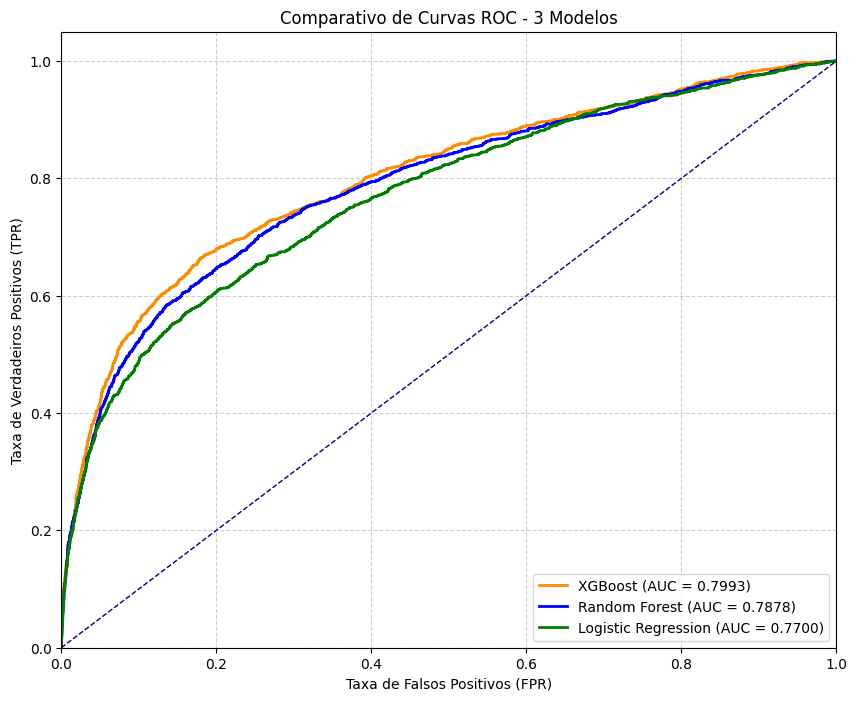

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 3. Terceiro modelo para comparação: Regressão Logística
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_processed, y_train)
y_proba_lr = lr_model.predict_proba(X_test_processed)[:, 1]
auc_lr = roc_auc_score(y_test, y_proba_lr)

# Cálculo das curvas ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)

# Plotagem
plt.figure(figsize=(10, 8))
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.4f})', color='darkorange', lw=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', color='blue', lw=2)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='green', lw=2)

# Linha de referência (aleatório)
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Comparativo de Curvas ROC - 3 Modelos')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Fase 4: Analise do melhor modelo



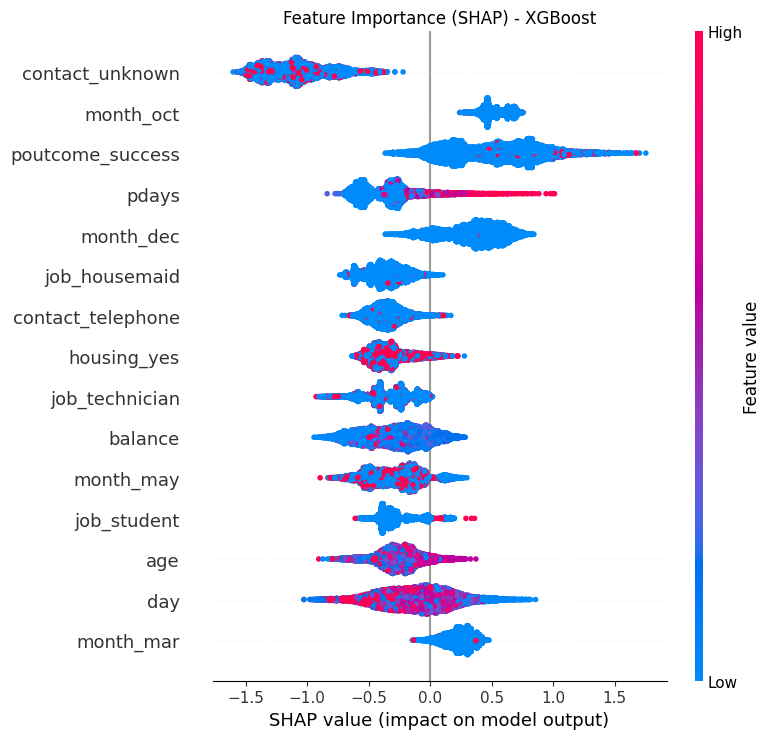

--- Relatório do Modelo Campeão (XGBoost) ---
              precision    recall  f1-score   support

           0       0.95      0.84      0.89     11977
           1       0.35      0.63      0.45      1587

    accuracy                           0.82     13564
   macro avg       0.65      0.74      0.67     13564
weighted avg       0.88      0.82      0.84     13564



In [16]:
import shap
import scipy.sparse

# Garantir estrutura compatível com SHAP
if scipy.sparse.issparse(X_test_processed):
    X_test_dense = X_test_processed.toarray()
else:
    X_test_dense = X_test_processed

X_test_df = pd.DataFrame(X_test_dense, columns=feature_names)

# Explicador aplicado ao modelo campeão real (best_model)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_df)

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_df, max_display=15, show=False)
plt.title(f'Feature Importance (SHAP) - {best_name}', fontsize=12)
plt.tight_layout()
plt.show()

print(f"--- Relatório do Modelo Campeão ({best_name}) ---")
print(classification_report(y_test, y_pred_best))

## Justificativa do Modelo Escolhido: **XGBoost**

O **XGBoost (Extreme Gradient Boosting)** foi selecionado como o modelo campeão do pipeline com base nos seguintes pilares técnicos e operacionais:

* **Desempenho Métrico Superior (ROC-AUC):** Atingiu a maior Área sob a Curva ROC do comparativo (**0.7993**), superando consistentemente a *Random Forest* (0.7878) e a *Regressão Logística* (0.7700) em ambiente de teste real não contaminado.
* **Tratamento Nativo do Desbalanceamento:** O uso estratégico do hiperparâmetro `scale_pos_weight` ajusta a penalidade da função de perda durante a otimização por gradiente. Isso permitiu ao modelo alcançar um **Recall de 63% na classe de conversão (y=1)** sem a necessidade de técnicas de ressampleamento artificial (como SMOTE ou Oversampling), preservando a integridade estatística e a distribuição real da base.
* **Ganhos em Relações Não-Lineares e Esparsidade:** Por trabalhar com decisões sequenciais (boosting de árvores rasas), o algoritmo performa significativamente melhor do que modelos lineares tradicionais ao lidar com matrizes altamente esparsas resultantes de codificação *One-Hot Encoding* (41 colunas).

### Interpretação e Importância dos Recursos (Análise SHAP)

A avaliação da caixa-preta do modelo **XGBoost** via **SHAP (SHapley Additive exPlanations)** expõe a contribuição marginal de cada variável para a probabilidade final de assinatura:

* **`poutcome_success` (Sucesso em Campanha Anterior):** É o principal direcionador positivo de conversão (*SHAP value* atingindo até +1.5). Ter uma conversão prévia é o maior indicador de fidelidade e propensão do cliente para novos produtos.
* **`contact_unknown` (Tipo de Contato Indeterminado):** Atua como o maior penalizador do *score* (*SHAP value* entre -0.5 e -1.5). A ausência de um canal de contato validado praticamente inviabiliza o sucesso da abordagem comercial.
* **Sazonalidade Comercial (`month_oct`, `month_mar`, `month_dec` vs `month_may`):**
  * Meses de fechamento de trimestres e períodos específicos como **Outubro, Março e Dezembro** possuem impacto fortemente positivo no valor SHAP.
  * Em contrapartida, o mês de **Maio (`month_may`)** possui impacto negativo expressivo no *output* do modelo, sugerindo um período de exaustão ou menor eficácia histórica de campanhas.
* **`housing_yes` (Empréstimo Habitacional Ativo):** Ter um financiamento imobiliário ativo reduz a propensão de assinatura (pontos vermelhos deslocados para a esquerda no gráfico SHAP) devido ao provável comprometimento prévio da renda mensal do cliente.
* **`balance` (Saldo Médio Anual) e `pdays` (Histórico de Contatos):**
  * Um saldo bancário mais elevado empurra as previsões para o espectro positivo (maior propensão de investimento).
  * Intervalos controlados e ativos de acompanhamento (`pdays`) aumentam significativamente a chance de conversão em relação a clientes que nunca haviam sido contatados anteriormente.

### Insights Acionáveis de Negócio

Com base no comportamento mapeado pelo modelo **XGBoost** e pelos *SHAP values*, definem-se as seguintes estratégias para a otimização da operação de marketing do banco:

#### A. Higienização e Priorização de Mailing
* **Ação - Atendimento VIP Prioritário:** Criar uma régua de atendimento ultra-prioritário no CRM para o segmento `poutcome_success`. Clientes convertidos no passado devem ser direcionados imediatamente para as equipes sêniores de conversão e assessoria financeira, dado que este é o canal mais propício ao re-investimento.
* **Ação - Otimização de Custos de Contato:** Suspender imediatamente abordagens telefônicas ativas e frias (de alto custo operacional) para clientes cujo contato esteja registrado como `unknown`. Submeter esse segmento primeiro a réguas automatizadas de enriquecimento de dados cadastrais via canais digitais de menor custo (WhatsApp, App, SMS ou E-mail).

#### B. Reestruturação do Calendário e Sazonalidade
* **Ação - Descompressão em Maio:** Descentralizar a força de vendas do mês de Maio (`month_may`). Historicamente, o banco concentra grandes volumes de ligações neste período, o que gera saturação operacional e retornos marginais decrescentes (baixa taxa de conversão relativa).
* **Ação - Realocação de Budget para Alta Propensão:** Redistribuir e concentrar o orçamento de marketing nos meses de **Março, Outubro e Dezembro**, períodos em que a resposta do cliente ao contato comercial é estatisticamente muito superior.

#### C. Oferta de Produtos Segmentada
* **Ação - Gestão de Alocação de Renda:** Evitar a oferta agressiva de depósitos a prazo fixo (que exigem imobilização de capital) para clientes com crédito imobiliário ativo (`housing == yes`). Para este perfil específico, priorizar produtos de investimento com maior liquidez e taxas de resgate flexíveis.
* **Ação - Micro-investimentos Customizados:** Desenhar e promover campanhas com tíquetes de entrada reduzidos e simplificados especificamente direcionadas a **Estudantes (`job_student`)** e **Aposentados (`retired`)**, capitalizando sobre a alta taxa de conversão proporcional demonstrada por estes grupos.

# Fase 5: Utilização do Modelo em Produção (Azure Databricks)

**Objetivo:** Projetar a arquitetura corporativa para operacionalização e servimento do modelo XGBoost em produção[cite: 3].

Proposta baseada no paradigma **Medallion Lakehouse** no **Azure Databricks**, garantindo governança, reprodutibilidade e MLOps de ponta a ponta:

1. **Camada de Dados (Medallion Architecture):**
   * **Bronze Layer:** Ingestão de dados brutos de interações do cliente via Databricks Auto Loader.
   * **Silver Layer:** Limpeza, validação de schemas, deduplicação e aplicação do pipeline de transformações.
   * **Gold Layer (Feature Store):** Tabela Delta contendo as features tratadas para consumo do modelo, com versionamento nativo no Databricks Feature Store.

2. **Rastreamento e Governança (MLflow + Unity Catalog):**
   * **MLflow Tracking:** Registro automático de experimentos, hiperparâmetros, artefatos (ColumnTransformer e XGBoost) e métricas de desempenho (ROC-AUC).
   * **Unity Catalog:** Gestão unificada de permissões (RBAC), linhagem de dados (*data lineage*) e controle do ciclo de vida do modelo (`Staging` -> `Production`).

3. **Estratégias de Servimento (Model Serving):**
   * **Batch Scoring (Estratégico):** Execução diária via *Databricks Workflows* para pontuar a base total de clientes elegíveis. A saída alimenta o CRM com a lista priorizada de propensão a conversão para o time comercial.
   * **Real-time API (Operacional):** Modelo exposto via *Databricks Model Serving Endpoints*. Requisições REST retornam o *score* de propensão do cliente em milissegundos durante o atendimento bancário.